# Multi-modal MI detection on PTB-XL: end-to-end notebook
Replication attempt of Setu et al. 2025 (ECG signal LSTM + ECG image CNN + attention fusion) on **PTB-XL only**.
Task: MI (any MI code, 5,469) vs. pure Normal (9,069). Split: folds 1-8 train / 9 val / 10 test (patient-wise).
Everything below is executed top to bottom; trained runs are cached in `runs/` so re-execution resumes.
Test fold 10 is scored once per model in section 7, after every choice is frozen on validation.

In [1]:
import os, sys, json, warnings
warnings.filterwarnings('ignore')
os.chdir(os.path.abspath('..')); sys.path.insert(0, os.getcwd())
import numpy as np, pandas as pd, torch, matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, precision_recall_curve, roc_auc_score
from src import config
from src.labels import build_labels, split_of
from src.train import fit_cached, get_data, predict, _batch
from src.evaluate import *
from src.utils import get_device
%matplotlib inline
plt.rcParams.update({'figure.dpi':110,'axes.spines.top':False,'axes.spines.right':False})
print('device', get_device(), '| torch', torch.__version__)

device cuda | torch 2.14.1+cu130


## 1. Data and label rule (frozen in Phase 1)

In [2]:
lab = build_labels(); lab['split'] = lab['fold'].map(split_of)
tab = lab.groupby('split').agg(n=('y','size'), mi=('y','sum'), patients=('patient_id','nunique'))
tab['mi_%'] = (100*tab.mi/tab.n).round(1); display(tab)
print('patient overlap train/val/test:', len(set(lab[lab.split=='train'].patient_id)&set(lab[lab.split!='train'].patient_id)))
age = lab.age.replace(300, 90)
print(lab.assign(age=age).groupby('y').agg(age=('age','mean'), male=('sex', lambda s:(s==1).mean())).round(2))

,n,mi,patients,mi_%
split,,,,
test,1462,550,1297,37.6
train,11622,4379,10396,37.7
val,1454,540,1338,37.1


patient overlap train/val/test: 0
     age  male
y             
0  52.12  0.55
1  66.79  0.38


## 2. Signals and rendered images (Phases 2-3)
Band-pass 0.5-40 Hz, per-lead z-score with train-fold statistics. Images: 12 stacked rows, 224x224, trace bright on dark, fixed ±3 mV per row. `paper` profile = 100 time steps, axis labels, JPEG; `ours` = 1000 steps, no text, lossless.

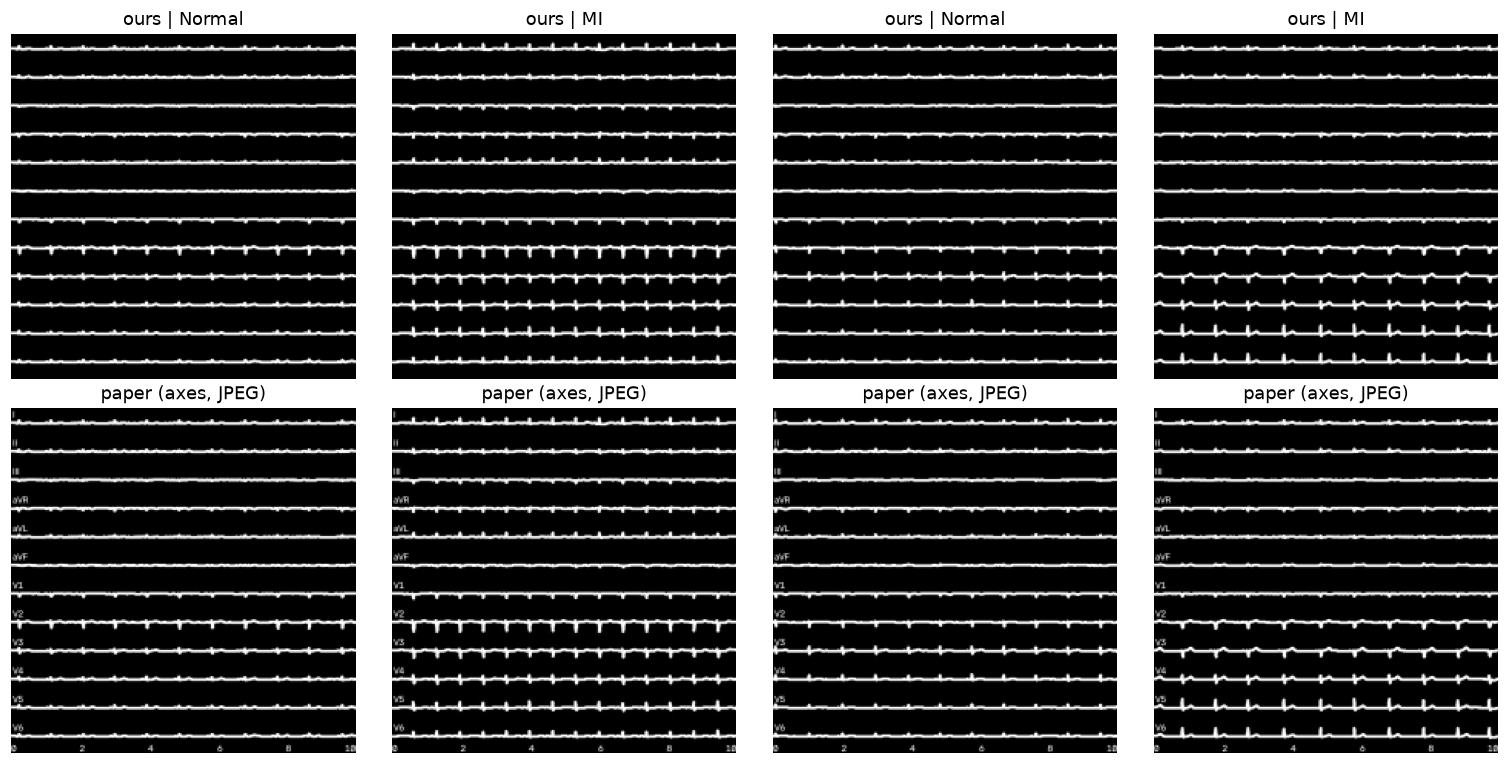

signals (14538, 1000, 12) finite True | train-fold mean/std -0.0 1.016
N images == N signals == N labels: True


In [3]:
from src.images import load_images
from src.signals import load_signals
ims_o, ims_p = load_images('ours'), load_images('paper')
fig, ax = plt.subplots(2, 4, figsize=(14, 7))
for j, i in enumerate([0, 1, 2, 3]):
    k = np.where(lab.y.values == (j % 2))[0][j]
    ax[0, j].imshow(ims_o[k], cmap='gray'); ax[0, j].set_title(f"ours | {'MI' if lab.y.iloc[k] else 'Normal'}")
    ax[1, j].imshow(ims_p[k], cmap='gray'); ax[1, j].set_title('paper (axes, JPEG)')
    [a.axis('off') for a in ax[:, j]]
plt.tight_layout(); plt.savefig(config.FIGURES_DIR/'render_grid.png'); plt.show()
x = load_signals(1000); print('signals', x.shape, 'finite', np.isfinite(x).all(), '| train-fold mean/std', x[(lab.split=='train').values].mean().round(3), x[(lab.split=='train').values].std().round(3))
# same-ecg_id sanity: image and signal for one record share the index
print('N images == N signals == N labels:', len(ims_o) == len(x) == len(lab))

## 3. Unimodal baselines (validation only, 3 seeds for cheap models)
B1 paper LSTM (100 steps) · B2 ResNet-1D (1000 steps) · B3 paper CNN (image, 224²). Adam, batch 32 (paper), early stopping on val AUROC. Trained on an RTX 3060 (CUDA; bf16 convs in the CNN branch).

In [4]:
yv = get_data('ours')['y'][get_data('ours')['split']=='val']
R = {}
for s in range(config.N_SEEDS):
    R[f'B1_s{s}'] = fit_cached('B1_lstm', f'B1_lstm_s{s}', seed=42+s, profile='paper', max_epochs=30, patience=6)
    R[f'B2_s{s}'] = fit_cached('B2_resnet1d', f'B2_resnet1d_s{s}', seed=42+s, profile='ours', max_epochs=25, patience=5)
R['B3_s0'] = fit_cached('B3_cnn', 'B3_cnn_s0', seed=42, profile='paper', bs=32, max_epochs=30, patience=5)
rows = []
for k, r in R.items():
    lo, hi = bootstrap_ci(yv, r['p_val']); rows.append(dict(run=k, val_auroc=round(r['val_auroc'],4), ci=f'[{lo:.3f}, {hi:.3f}]', epochs=r['epochs']))
base = pd.DataFrame(rows); display(base)
print(base.assign(m=base.run.str.split('_').str[0]).groupby('m').val_auroc.agg(['mean','std']).round(4))

[cached] B1_lstm_s0 val_auroc=0.9515
[cached] B2_resnet1d_s0 val_auroc=0.9729
[cached] B1_lstm_s1 val_auroc=0.9524
[cached] B2_resnet1d_s1 val_auroc=0.9757
[cached] B1_lstm_s2 val_auroc=0.9522
[cached] B2_resnet1d_s2 val_auroc=0.9738
[cached] B3_cnn_s0 val_auroc=0.9665


,run,val_auroc,ci,epochs
0,B1_s0,0.9515,"[0.940, 0.962]",20
1,B2_s0,0.9729,"[0.965, 0.980]",15
2,B1_s1,0.9524,"[0.940, 0.963]",20
3,B2_s1,0.9757,"[0.969, 0.982]",14
4,B1_s2,0.9522,"[0.941, 0.962]",17
5,B2_s2,0.9738,"[0.966, 0.980]",13
6,B3_s0,0.9665,"[0.957, 0.975]",30


      mean     std
m                 
B1  0.9520  0.0005
B2  0.9741  0.0014
B3  0.9665     NaN


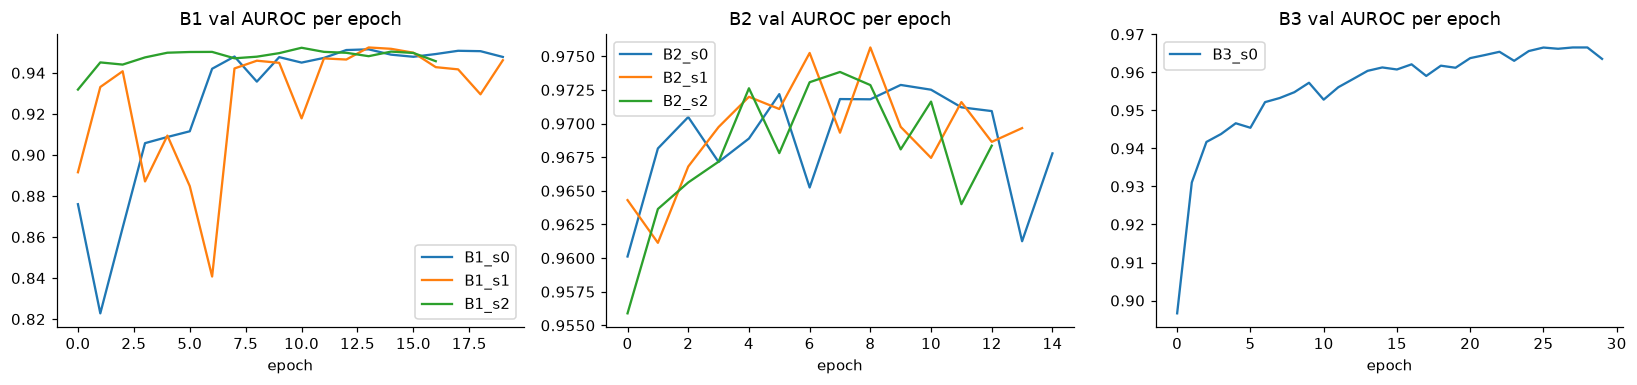

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
for a, pre in zip(ax, ['B1','B2','B3']):
    for k, r in R.items():
        if k.startswith(pre): a.plot([h['val_auroc'] for h in r['history']], label=k); 
    a.set_title(pre+' val AUROC per epoch'); a.set_xlabel('epoch'); a.legend()
plt.tight_layout(); plt.savefig(config.FIGURES_DIR/'baseline_curves.png'); plt.show()

## 4. Multi-modal fusion (paper architecture) and controls
CNN branch (image, 128) + LSTM branch (signal, 100 steps, 128) → attention fusion R1 (our reading) / R2 (Keras reading) / concat control; late fusion = mean of B1 and B3 probabilities. Trained end to end from scratch on the `paper` profile.

[cached] F_r1_s0 val_auroc=0.9509
[cached] F_r2_s0 val_auroc=0.9496
[cached] F_concat_s0 val_auroc=0.9650


,model,val_auroc,ci
0,B1 LSTM (s0),0.9515,"[0.940, 0.962]"
1,B2 ResNet1D (s0),0.9729,"[0.965, 0.980]"
2,B3 CNN,0.9665,"[0.957, 0.975]"
3,Late fusion B1+B3,0.9644,"[0.955, 0.973]"
4,Concat fusion,0.9650,"[0.956, 0.974]"
5,Attention R1,0.9509,"[0.938, 0.961]"
6,Attention R2,0.9496,"[0.938, 0.961]"


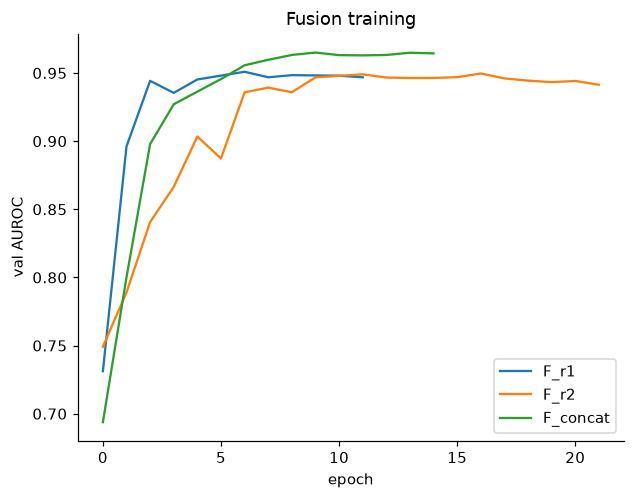

In [6]:
for n in ['F_r1','F_r2','F_concat']:
    R[n] = fit_cached(n, n+'_s0', seed=42, profile='paper', bs=32, max_epochs=30, patience=5)
pl = (R['B1_s0']['p_val'] + R['B3_s0']['p_val'])/2
rows = []
for k, p in [('B1 LSTM (s0)',R['B1_s0']['p_val']),('B2 ResNet1D (s0)',R['B2_s0']['p_val']),('B3 CNN',R['B3_s0']['p_val']),
             ('Late fusion B1+B3',pl),('Concat fusion',R['F_concat']['p_val']),('Attention R1',R['F_r1']['p_val']),('Attention R2',R['F_r2']['p_val'])]:
    lo, hi = bootstrap_ci(yv, p); rows.append(dict(model=k, val_auroc=round(roc_auc_score(yv,p),4), ci=f'[{lo:.3f}, {hi:.3f}]'))
fus = pd.DataFrame(rows); display(fus)
for n in ['F_r1','F_r2','F_concat']:
    h = pd.DataFrame(R[n]['history']); plt.plot(h.val_auroc, label=n)
plt.legend(); plt.xlabel('epoch'); plt.ylabel('val AUROC'); plt.title('Fusion training'); plt.savefig(config.FIGURES_DIR/'fusion_curves.png'); plt.show()

## 5. Tuning (validation only, equal small budget for the two cheap signal models)
Learning rate {3e-4, 1e-3, 3e-3} for B1 and B2 (3 trials each, seed 42). The image and fusion models keep the paper's lr 1e-3 (not tuned); this is stated as a limitation, and it favours the signal baselines.

In [7]:
T = []
for name, prof, ep in [('B1_lstm','paper',30), ('B2_resnet1d','ours',25)]:
    for lr in (3e-4, 1e-3, 3e-3):
        r = fit_cached(name, f'tune_{name}_lr{lr}', seed=42, lr=lr, profile=prof, max_epochs=ep, patience=5)
        T.append(dict(model=name, lr=lr, val_auroc=round(r['val_auroc'],4)))
tune = pd.DataFrame(T); display(tune.pivot(index='lr', columns='model', values='val_auroc'))
best_lr = tune.loc[tune.groupby('model').val_auroc.idxmax()].set_index('model').lr.to_dict(); print('frozen lr:', best_lr)

[cached] tune_B1_lstm_lr0.0003 val_auroc=0.9532
[cached] tune_B1_lstm_lr0.001 val_auroc=0.9515
[cached] tune_B1_lstm_lr0.003 val_auroc=0.9558
[cached] tune_B2_resnet1d_lr0.0003 val_auroc=0.9716
[cached] tune_B2_resnet1d_lr0.001 val_auroc=0.9729
[cached] tune_B2_resnet1d_lr0.003 val_auroc=0.9736


model,B1_lstm,B2_resnet1d
lr,,
0.0003,0.9532,0.9716
0.0010,0.9515,0.9729
0.0030,0.9558,0.9736


frozen lr: {'B1_lstm': 0.003, 'B2_resnet1d': 0.003}


In [8]:
# Frozen final runs: 3 seeds at the tuned lr for B1/B2
FIN = {}
for name, prof, ep, tag in [('B1_lstm','paper',30,'B1'), ('B2_resnet1d','ours',25,'B2')]:
    for s in range(config.N_SEEDS):
        FIN[f'{tag}_s{s}'] = fit_cached(name, f'final_{name}_s{s}', seed=42+s, lr=best_lr[name], profile=prof, max_epochs=ep, patience=5)
for tag in ('B1','B2'):
    a = [FIN[f'{tag}_s{s}']['val_auroc'] for s in range(config.N_SEEDS)]; print(tag, 'val AUROC mean±sd', np.mean(a).round(4), np.std(a).round(4))
FIN['B3'], FIN['F_r1'], FIN['F_r2'], FIN['F_concat'] = R['B3_s0'], R['F_r1'], R['F_r2'], R['F_concat']
# seed-ensemble probabilities for the signal models, single run for the image/fusion models
P_val = {'B1 LSTM': np.mean([FIN[f'B1_s{s}']['p_val'] for s in range(3)],0), 'B2 ResNet1D': np.mean([FIN[f'B2_s{s}']['p_val'] for s in range(3)],0),
         'B3 CNN': R['B3_s0']['p_val'], 'Concat': R['F_concat']['p_val'], 'Attn R1': R['F_r1']['p_val'], 'Attn R2': R['F_r2']['p_val']}
P_test = {'B1 LSTM': np.mean([FIN[f'B1_s{s}']['p_test'] for s in range(3)],0), 'B2 ResNet1D': np.mean([FIN[f'B2_s{s}']['p_test'] for s in range(3)],0),
          'B3 CNN': R['B3_s0']['p_test'], 'Concat': R['F_concat']['p_test'], 'Attn R1': R['F_r1']['p_test'], 'Attn R2': R['F_r2']['p_test']}
P_val['Late B1+B3'] = (P_val['B1 LSTM']+P_val['B3 CNN'])/2; P_test['Late B1+B3'] = (P_test['B1 LSTM']+P_test['B3 CNN'])/2
print(pd.Series({k: round(roc_auc_score(yv,v),4) for k,v in P_val.items()}, name='val AUROC (frozen)'))

[cached] final_B1_lstm_s0 val_auroc=0.9558
[cached] final_B1_lstm_s1 val_auroc=0.9531
[cached] final_B1_lstm_s2 val_auroc=0.9532
[cached] final_B2_resnet1d_s0 val_auroc=0.9736
[cached] final_B2_resnet1d_s1 val_auroc=0.9747
[cached] final_B2_resnet1d_s2 val_auroc=0.9708
B1 val AUROC mean±sd 0.954 0.0013
B2 val AUROC mean±sd 0.9731 0.0016
B1 LSTM        0.9579
B2 ResNet1D    0.9762
B3 CNN         0.9665
Concat         0.9650
Attn R1        0.9509
Attn R2        0.9496
Late B1+B3     0.9670
Name: val AUROC (frozen), dtype: float64


## 6. Ablations (validation, paired bootstrap ΔAUROC)
A1/A2 from the frozen models; A3 sequence length for the LSTM; A7 noisy records; A9 augmentation for the CNN is skipped (cost), see report.

In [9]:
rows = []
for a, b in [('Attn R1','B1 LSTM'),('Attn R1','B2 ResNet1D'),('Attn R1','Concat'),('Attn R1','Late B1+B3'),('Attn R1','Attn R2'),('B2 ResNet1D','B1 LSTM'),('B1 LSTM','B3 CNN')]:
    d, lo, hi = paired_delta_auc(yv, P_val[a], P_val[b]); rows.append(dict(A=a, B=b, dAUROC=round(d,4), ci=f'[{lo:.3f}, {hi:.3f}]', sig=('yes' if lo>0 or hi<0 else 'no')))
display(pd.DataFrame(rows))

,A,B,dAUROC,ci,sig
0,Attn R1,B1 LSTM,-0.0069,"[-0.012, -0.002]",yes
1,Attn R1,B2 ResNet1D,-0.0252,"[-0.034, -0.018]",yes
2,Attn R1,Concat,-0.0141,"[-0.022, -0.006]",yes
3,Attn R1,Late B1+B3,-0.0161,"[-0.022, -0.011]",yes
4,Attn R1,Attn R2,0.0013,"[-0.003, 0.005]",no
5,B2 ResNet1D,B1 LSTM,0.0183,"[0.012, 0.026]",yes
6,B1 LSTM,B3 CNN,-0.0087,"[-0.017, -0.001]",yes


In [10]:
# A3: LSTM input length (seed 42, tuned lr). 100 steps = paper profile
A3 = []
for L in (100, 250, 500, 1000):
    r = fit_cached('B1_lstm', f'abl_A3_L{L}', seed=42, lr=best_lr['B1_lstm'], profile='ours', seq_len=L, max_epochs=20 if L<=250 else 12, patience=4)
    A3.append(dict(seq_len=L, val_auroc=round(r['val_auroc'],4)))
display(pd.DataFrame(A3))

[cached] abl_A3_L100 val_auroc=0.9558
[cached] abl_A3_L250 val_auroc=0.9696
[cached] abl_A3_L500 val_auroc=0.9731
[cached] abl_A3_L1000 val_auroc=0.9712


,seq_len,val_auroc
0,100,0.9558
1,250,0.9696
2,500,0.9731
3,1000,0.9712


In [11]:
# A7: noisy vs clean validation records (baseline drift / static / burst noise flagged)
noisy = lab[['baseline_drift','static_noise','burst_noise','electrodes_problems']].notna().any(axis=1).values
vm = (lab.split=='val').values; nv = noisy[vm]
for k in ['B1 LSTM','B2 ResNet1D','B3 CNN','Attn R1']:
    print(f'{k:12s} clean AUROC {roc_auc_score(yv[~nv],P_val[k][~nv]):.4f} (n={int((~nv).sum())}) | noisy {roc_auc_score(yv[nv],P_val[k][nv]):.4f} (n={int(nv.sum())})')

B1 LSTM      clean AUROC 0.9601 (n=1099) | noisy 0.9543 (n=355)
B2 ResNet1D  clean AUROC 0.9760 (n=1099) | noisy 0.9767 (n=355)
B3 CNN       clean AUROC 0.9678 (n=1099) | noisy 0.9633 (n=355)
Attn R1      clean AUROC 0.9551 (n=1099) | noisy 0.9422 (n=355)


## 7. Final test evaluation (fold 10, once per model)
Threshold = Youden J chosen on validation. Test log is written to `results/test_evaluation_log.json`; a second run for the same model is refused.

In [12]:
yt = get_data('ours')['y'][get_data('ours')['split']=='test']
logged = {r['model'] for r in json.loads(TEST_LOG.read_text())} if TEST_LOG.exists() else set()
TR = {}
for k in P_val:
    thr = youden_threshold(yv, P_val[k]); m = metrics(yt, P_test[k], thr); m['auroc_ci'] = bootstrap_ci(yt, P_test[k])
    TR[k] = m
    if k not in logged: log_test_run(k, m)
res = pd.DataFrame(TR).T[['auroc','auroc_ci','auprc','f1','sensitivity','specificity','brier','threshold']]
res[['auroc','auprc','f1','sensitivity','specificity','brier','threshold']] = res[['auroc','auprc','f1','sensitivity','specificity','brier','threshold']].astype(float).round(4)
res.to_csv(config.RESULTS_DIR/'test_results.csv'); display(res)

,auroc,auroc_ci,auprc,f1,sensitivity,specificity,brier,threshold
B1 LSTM,0.9482,"(0.935746, 0.959252)",0.9400,0.8551,0.8582,0.9101,0.0773,0.3492
B2 ResNet1D,0.9698,"(0.961134, 0.977586)",0.9609,0.8754,0.8236,0.9649,0.0632,0.5620
B3 CNN,0.9608,"(0.950927, 0.969687)",0.9507,0.8661,0.8527,0.9298,0.0829,0.1661
Concat,0.9522,"(0.941427, 0.963074)",0.9409,0.8574,0.8364,0.9309,0.0867,0.2152
Attn R1,0.9361,"(0.922493, 0.948186)",0.9252,0.8304,0.8145,0.9112,0.0880,0.3158
Attn R2,0.9362,"(0.921444, 0.948752)",0.9281,0.8534,0.8255,0.9342,0.0848,0.3768
Late B1+B3,0.9595,"(0.948701, 0.968741)",0.9521,0.8764,0.8636,0.9353,0.0727,0.2834


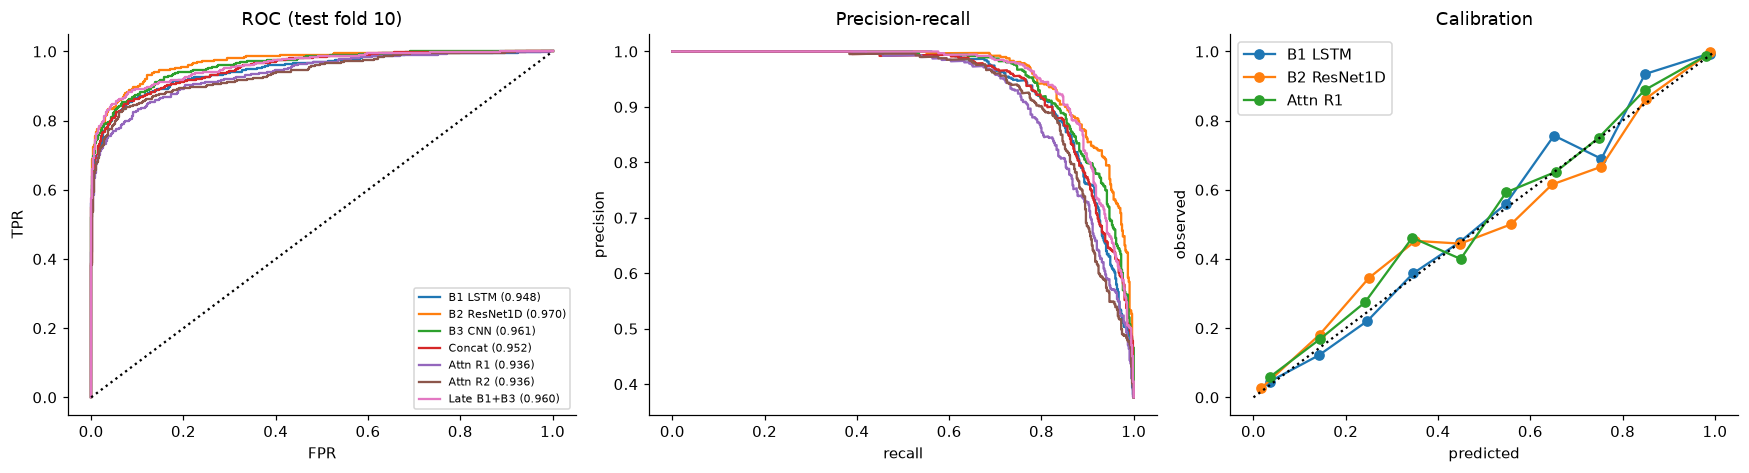

In [13]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.4))
for k in P_test:
    f, t, _ = roc_curve(yt, P_test[k]); ax[0].plot(f, t, label=f'{k} ({TR[k]["auroc"]:.3f})')
    p, r, _ = precision_recall_curve(yt, P_test[k]); ax[1].plot(r, p, label=k)
ax[0].plot([0,1],[0,1],'k:'); ax[0].set_title('ROC (test fold 10)'); ax[0].set_xlabel('FPR'); ax[0].set_ylabel('TPR'); ax[0].legend(fontsize=7)
ax[1].set_title('Precision-recall'); ax[1].set_xlabel('recall'); ax[1].set_ylabel('precision')
from sklearn.calibration import calibration_curve
for k in ['B1 LSTM','B2 ResNet1D','Attn R1']:
    fp, mp = calibration_curve(yt, P_test[k], n_bins=10); ax[2].plot(mp, fp, 'o-', label=k)
ax[2].plot([0,1],[0,1],'k:'); ax[2].set_title('Calibration'); ax[2].set_xlabel('predicted'); ax[2].set_ylabel('observed'); ax[2].legend()
plt.tight_layout(); plt.savefig(config.FIGURES_DIR/'test_curves.png'); plt.show()

In [14]:
rows = []
for a, b in [('Attn R1','B1 LSTM'),('Attn R1','B2 ResNet1D'),('Attn R1','Concat'),('B2 ResNet1D','B1 LSTM'),('B2 ResNet1D','B3 CNN')]:
    d, lo, hi = paired_delta_auc(yt, P_test[a], P_test[b]); rows.append(dict(A=a, B=b, dAUROC=round(d,4), ci=f'[{lo:.3f}, {hi:.3f}]'))
display(pd.DataFrame(rows))
# subgroups on test (best signal model and fusion)
te = lab[lab.split=='test'].copy(); te['age_band'] = pd.cut(te.age.replace(300,90), [0,50,65,80,120], labels=['<50','50-65','65-80','80+'])
te['mi_sub'] = te.mi_subclass.apply(lambda s: ','.join(s))
sub = []
for name, mask in [('male', te.sex==1), ('female', te.sex==0)] + [(f'age {b}', te.age_band==b) for b in ['<50','50-65','65-80','80+']] + [('clean', ~noisy[(lab.split=='test').values]), ('noisy', noisy[(lab.split=='test').values])]:
    mk = np.asarray(mask)
    if len(set(yt[mk]))==2: sub.append(dict(group=name, n=int(mk.sum()), **{k: round(roc_auc_score(yt[mk], P_test[k][mk]),3) for k in ['B1 LSTM','B2 ResNet1D','Attn R1']}))
display(pd.DataFrame(sub))
for s in ['IMI','AMI']:
    mk = (te.mi_sub.str.contains(s) | (te.y==0)).values
    print(s, 'vs Normal, n_MI =', int(te.mi_sub.str.contains(s).sum()), {k: round(roc_auc_score(yt[mk], P_test[k][mk]),3) for k in ['B1 LSTM','B2 ResNet1D','Attn R1']})

,A,B,dAUROC,ci
0,Attn R1,B1 LSTM,-0.0121,"[-0.018, -0.006]"
1,Attn R1,B2 ResNet1D,-0.0337,"[-0.045, -0.024]"
2,Attn R1,Concat,-0.0161,"[-0.026, -0.006]"
3,B2 ResNet1D,B1 LSTM,0.0217,"[0.013, 0.031]"
4,B2 ResNet1D,B3 CNN,0.0091,"[0.001, 0.016]"


,group,n,B1 LSTM,B2 ResNet1D,Attn R1
0,male,680,0.943,0.963,0.934
1,female,782,0.952,0.976,0.938
2,age <50,447,0.912,0.964,0.904
3,age 50-65,445,0.890,0.934,0.859
4,age 65-80,417,0.954,0.973,0.935
5,age 80+,153,0.938,0.953,0.939
6,clean,1102,0.953,0.974,0.941
7,noisy,360,0.932,0.957,0.926


IMI vs Normal, n_MI = 327 {'B1 LSTM': 0.941, 'B2 ResNet1D': 0.968, 'Attn R1': 0.929}
AMI vs Normal, n_MI = 306 {'B1 LSTM': 0.972, 'B2 ResNet1D': 0.981, 'Attn R1': 0.963}


## 8. Explainability and error analysis
Grad-CAM on the paper CNN (last conv), gradient saliency on the LSTM signal branch, attention weights of fusion R1, then a review of test errors of the best model.

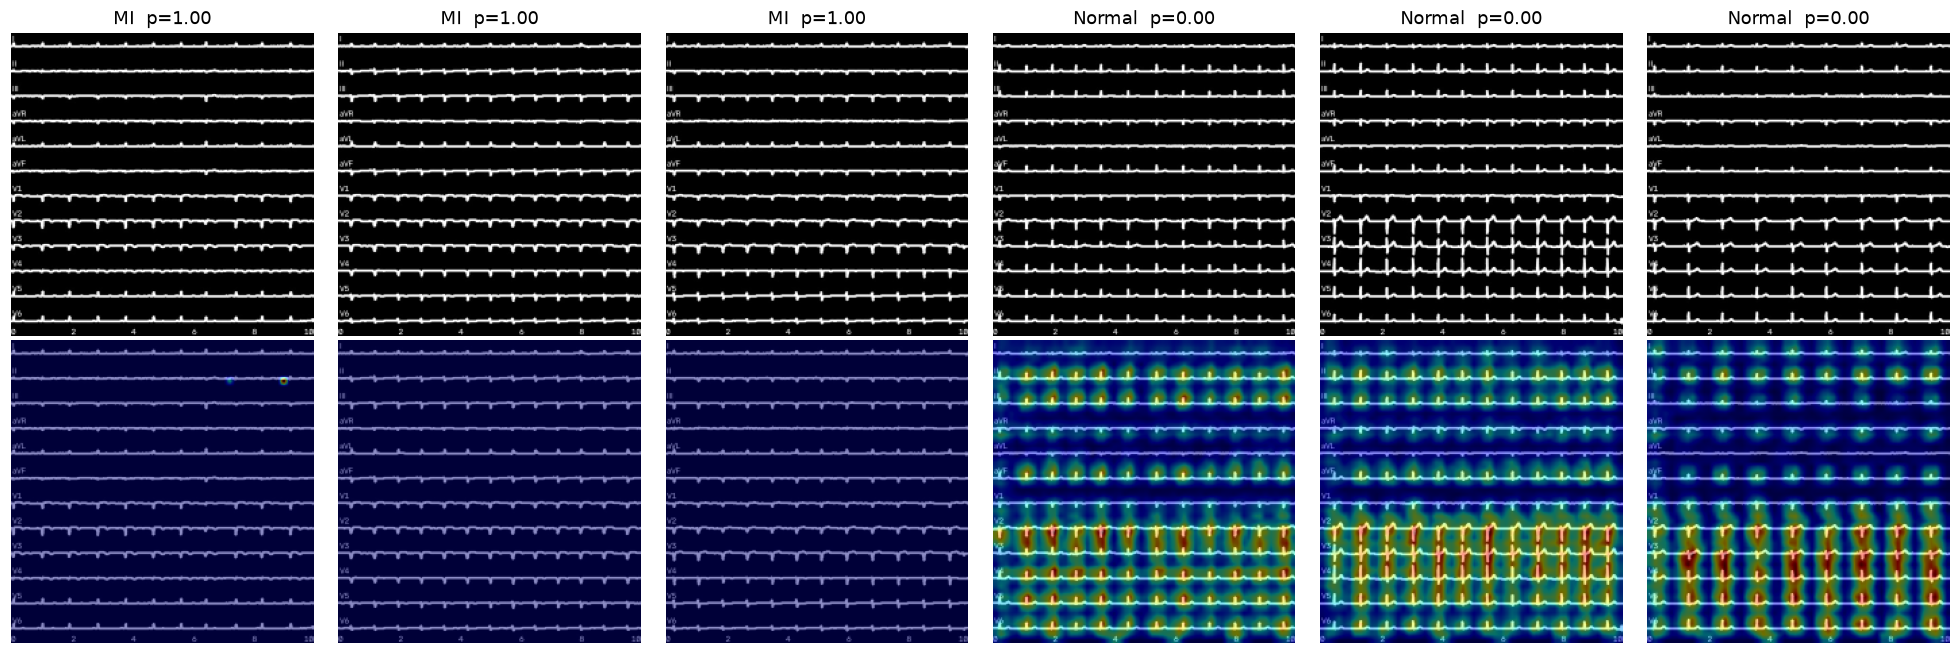

,I,II,III,aVR,aVL,aVF,V1,V2,V3,V4,V5,V6
MI (detected),0.015,0.008,0.009,0.012,0.011,0.006,0.013,0.024,0.026,0.022,0.017,0.014
Normal,0.223,0.202,0.113,0.159,0.136,0.118,0.192,0.364,0.381,0.342,0.313,0.264


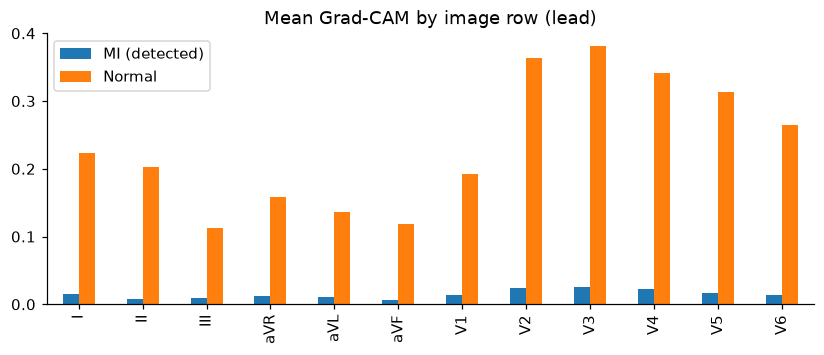

In [15]:
dev = get_device(); d = get_data('paper'); te_ids = np.where(d['split']=='test')[0]
cnn = R['B3_s0']['model'].to(dev).eval()
def gradcam(img):
    acts = {}
    layer = [m for m in cnn.branch.conv if isinstance(m, torch.nn.Conv2d)][-1]
    h1 = layer.register_forward_hook(lambda m,i,o: acts.__setitem__('a', o)); x = img.clone().requires_grad_(True)
    out = cnn(x, None); h1.remove(); g = torch.autograd.grad(out.sum(), acts['a'])[0]
    w = g.mean((2,3), keepdim=True); cam = torch.relu((w*acts['a']).sum(1, keepdim=True)).float()
    cam = torch.nn.functional.interpolate(cam, size=img.shape[-2:], mode='bilinear')[0,0].detach().cpu().numpy()
    return cam/(cam.max()+1e-9)
pm = P_test['B3 CNN']; yy = yt
sel = [te_ids[i] for i in np.argsort(-pm*(yy==1))[:3]] + [te_ids[i] for i in np.argsort(pm+10*(yy==1))[:3]]
fig, ax = plt.subplots(2, 6, figsize=(18, 6))
for j, k in enumerate(sel):
    img, _ = _batch(d, torch.tensor([k]), dev); cam = gradcam(img)
    ax[0, j].imshow(d['img'][k], cmap='gray'); ax[0, j].set_title(f"{'MI' if d['y'][k] else 'Normal'}  p={pm[list(te_ids).index(k)]:.2f}")
    ax[1, j].imshow(d['img'][k], cmap='gray'); ax[1, j].imshow(cam, cmap='jet', alpha=0.45); [a.axis('off') for a in ax[:, j]]
plt.tight_layout(); plt.savefig(config.FIGURES_DIR/'gradcam.png'); plt.show()
# lead-wise mean CAM for correctly detected MI vs. Normal
rows = np.array_split(np.arange(224), 12)
def leadcam(idxs):
    return np.mean([[gradcam(_batch(d, torch.tensor([k]), dev)[0])[r].mean() for r in rows] for k in idxs], 0)
mi_ok = [te_ids[i] for i in np.where((yy==1)&(pm>0.5))[0][:40]]; nm_ok = [te_ids[i] for i in np.where((yy==0)&(pm<0.5))[0][:40]]
lc = pd.DataFrame({'MI (detected)': leadcam(mi_ok), 'Normal': leadcam(nm_ok)}, index=config.LEADS).round(3); display(lc.T)
lc.plot.bar(figsize=(9,3.2), title='Mean Grad-CAM by image row (lead)'); plt.savefig(config.FIGURES_DIR/'gradcam_leads.png'); plt.show()

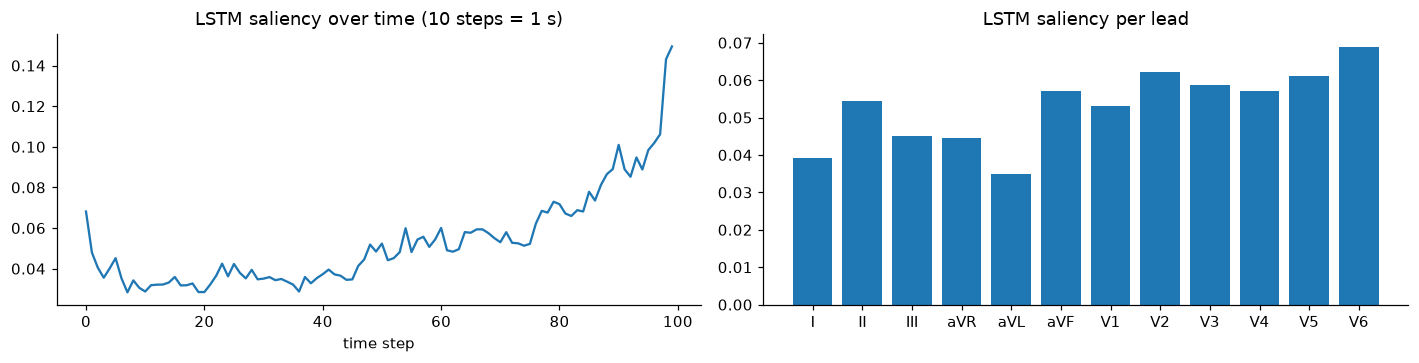

,img<-img,img<-sig,sig<-img,sig<-sig
y,,,,
0.0,0.598,0.402,0.539,0.461
1.0,0.504,0.496,0.462,0.538


R1 attention weights stay near 0.5/0.5 if |img<-img - 0.5| is small


In [16]:
# gradient saliency on the LSTM (seed 0), averaged over detected MI test records
lstm = FIN['B1_s0']['model'].to(dev).eval(); ds = get_data('paper')
ids = [te_ids[i] for i in np.where((yy==1)&(P_test['B1 LSTM']>0.5))[0][:200]]
S = []
for i in range(0, len(ids), 50):
    x = ds['sig'][ids[i:i+50]].to(dev).requires_grad_(True)
    with torch.backends.cudnn.flags(enabled=False):
        lstm.train(); lstm(None, x).sum().backward(); lstm.eval()
    S.append(x.grad.abs().cpu().numpy())
S = np.concatenate(S).mean(0)                              # (100, 12)
fig, ax = plt.subplots(1, 2, figsize=(13, 3.4))
ax[0].plot(S.mean(1)); ax[0].set_title('LSTM saliency over time (10 steps = 1 s)'); ax[0].set_xlabel('time step')
ax[1].bar(config.LEADS, S.mean(0)); ax[1].set_title('LSTM saliency per lead'); plt.tight_layout(); plt.savefig(config.FIGURES_DIR/'saliency.png'); plt.show()
# attention weights R1
fr1 = FIN['F_r1']['model'].to(dev).eval(); W = []
for i in range(0, len(te_ids), 128):
    ii = torch.tensor(te_ids[i:i+128]); fr1(*_batch(d, ii, dev)); W.append(fr1.last_attn.cpu().numpy())
W = np.concatenate(W); att = pd.DataFrame({'y': yy, 'img<-img': W[:,0,0], 'img<-sig': W[:,0,1], 'sig<-img': W[:,1,0], 'sig<-sig': W[:,1,1]})
display(att.groupby('y').mean().round(3)); print('R1 attention weights stay near 0.5/0.5 if |img<-img - 0.5| is small')

In [17]:
# 50 test errors (25 FN, 25 FP) for the best test model by AUROC
best = max(TR, key=lambda k: TR[k]['auroc']); thr = TR[best]['threshold']; print('best test model:', best)
te = lab[lab.split=='test'].copy(); te['p'] = P_test[best]
fn = te[(te.y==1)&(te.p<thr)].sort_values('p').head(25); fp = te[(te.y==0)&(te.p>=thr)].sort_values('p', ascending=False).head(25)
err = pd.concat([fn.assign(kind='FN'), fp.assign(kind='FP')])[['kind','p','age','sex','mi_subclass','infarction_stadium1','static_noise','baseline_drift','device']]
display(err.head(12)); err.to_csv(config.RESULTS_DIR/'error_review.csv')
allfn = te[(te.y==1)&(te.p<thr)]
print('FN total', len(allfn), '| stadium mix:', allfn.infarction_stadium1.fillna('unknown').value_counts().to_dict())
print('FN noisy share', round(float(allfn[['baseline_drift','static_noise','burst_noise']].notna().any(axis=1).mean()),2), 'vs overall MI test', round(float(te[te.y==1][['baseline_drift','static_noise','burst_noise']].notna().any(axis=1).mean()),2))
print('FN subclass mix:', allfn.mi_subclass.apply(lambda s: ','.join(s)).value_counts().head(5).to_dict())

best test model: B2 ResNet1D


,kind,p,age,sex,mi_subclass,infarction_stadium1,static_noise,baseline_drift,device
ecg_id,,,,,,,,,
1447,FN,0.000699,64.0,1,[AMI],unknown,", I,II,AVL,AVR,",NaN,AT-6 C
7895,FN,0.001511,61.0,0,[IMI],unknown,NaN,NaN,CS-12
799,FN,0.008030,61.0,0,[IMI],unknown,", I-AVR,",", II,III,AVF",CS-12 E
17575,FN,0.008636,53.0,0,[AMI],unknown,", I-AVR,",NaN,CS-12 E
10828,FN,0.008814,54.0,1,[AMI],unknown,NaN,", II-AVF",CS-12 E
19017,FN,0.019473,63.0,1,[IMI],unknown,NaN,NaN,CS-12
1901,FN,0.021926,17.0,1,[AMI],unknown,NaN,NaN,CS-12 E
12137,FN,0.039800,84.0,1,[AMI],unknown,NaN,NaN,AT-6 6
16712,FN,0.040914,48.0,1,[IMI],unknown,NaN,NaN,CS-12


FN total 97 | stadium mix: {'unknown': 68, 'Stadium II-III': 20, 'Stadium III': 8, 'Stadium I': 1}
FN noisy share 0.29 vs overall MI test 0.26
FN subclass mix: {'IMI': 61, 'AMI': 30, 'LMI': 5, 'AMI,LMI': 1}


## 9. Summary

In [18]:
summary = res[['auroc','auroc_ci','sensitivity','specificity']]; display(summary)
res.to_csv(config.RESULTS_DIR/'final_summary.csv')
print('Best test AUROC:', best, round(TR[best]['auroc'],4), '| fusion R1:', round(TR['Attn R1']['auroc'],4), '| B1 LSTM:', round(TR['B1 LSTM']['auroc'],4), '| B2 ResNet1D:', round(TR['B2 ResNet1D']['auroc'],4))

,auroc,auroc_ci,sensitivity,specificity
B1 LSTM,0.9482,"(0.935746, 0.959252)",0.8582,0.9101
B2 ResNet1D,0.9698,"(0.961134, 0.977586)",0.8236,0.9649
B3 CNN,0.9608,"(0.950927, 0.969687)",0.8527,0.9298
Concat,0.9522,"(0.941427, 0.963074)",0.8364,0.9309
Attn R1,0.9361,"(0.922493, 0.948186)",0.8145,0.9112
Attn R2,0.9362,"(0.921444, 0.948752)",0.8255,0.9342
Late B1+B3,0.9595,"(0.948701, 0.968741)",0.8636,0.9353


Best test AUROC: B2 ResNet1D 0.9698 | fusion R1: 0.9361 | B1 LSTM: 0.9482 | B2 ResNet1D: 0.9698
